In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [4]:
noisy_curvefit_data = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")

In [6]:
print(f'Shape of dataset: {noisy_curvefit_data.shape}')
print(f'# of rows: {noisy_curvefit_data.shape[0]}, # of columns: {noisy_curvefit_data.shape[1]}')
display(noisy_curvefit_data.head()) #First 5 rows
display(noisy_curvefit_data.tail()) #Last 5 rows
print(f'Column names: {list(noisy_curvefit_data.columns)}')

Shape of dataset: (100, 6)
# of rows: 100, # of columns: 6


,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


Column names: ['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']


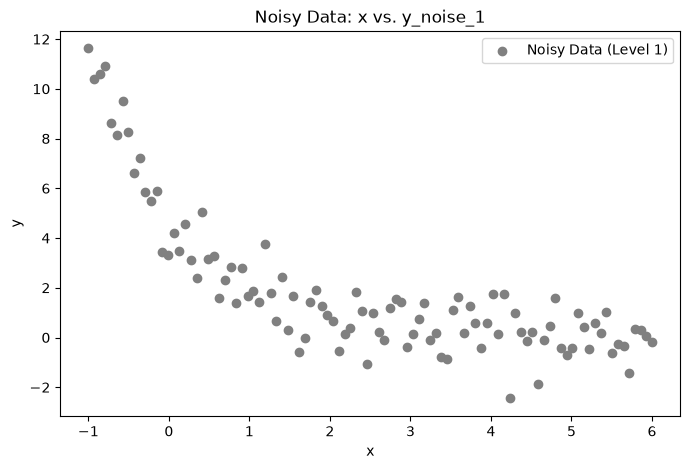

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(noisy_curvefit_data["x"], noisy_curvefit_data["y_noise_1"], color="gray", label="Noisy Data (Level 1)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy Data: x vs. y_noise_1")
plt.legend()
plt.show()

Fit: y= 4.71 * e^(- 0.92 * x)


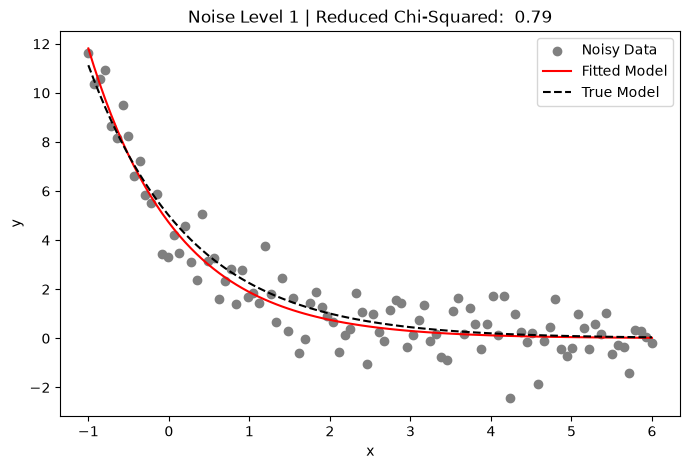

In [9]:
x = noisy_curvefit_data["x"]
y_noise_1 = noisy_curvefit_data["y_noise_1"]

def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt
print(f'Fit: y= {A_fit:.2f} * e^(-{k_fit: .2f} * x)')

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

plt.figure(figsize=(8, 5))
plt.scatter(x, y_noise_1, color="gray", label="Noisy Data")
plt.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted Model")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True Model")

plt.title(f"Noise Level 1 | Reduced Chi-Squared: {chi2_reduced: .2f}")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

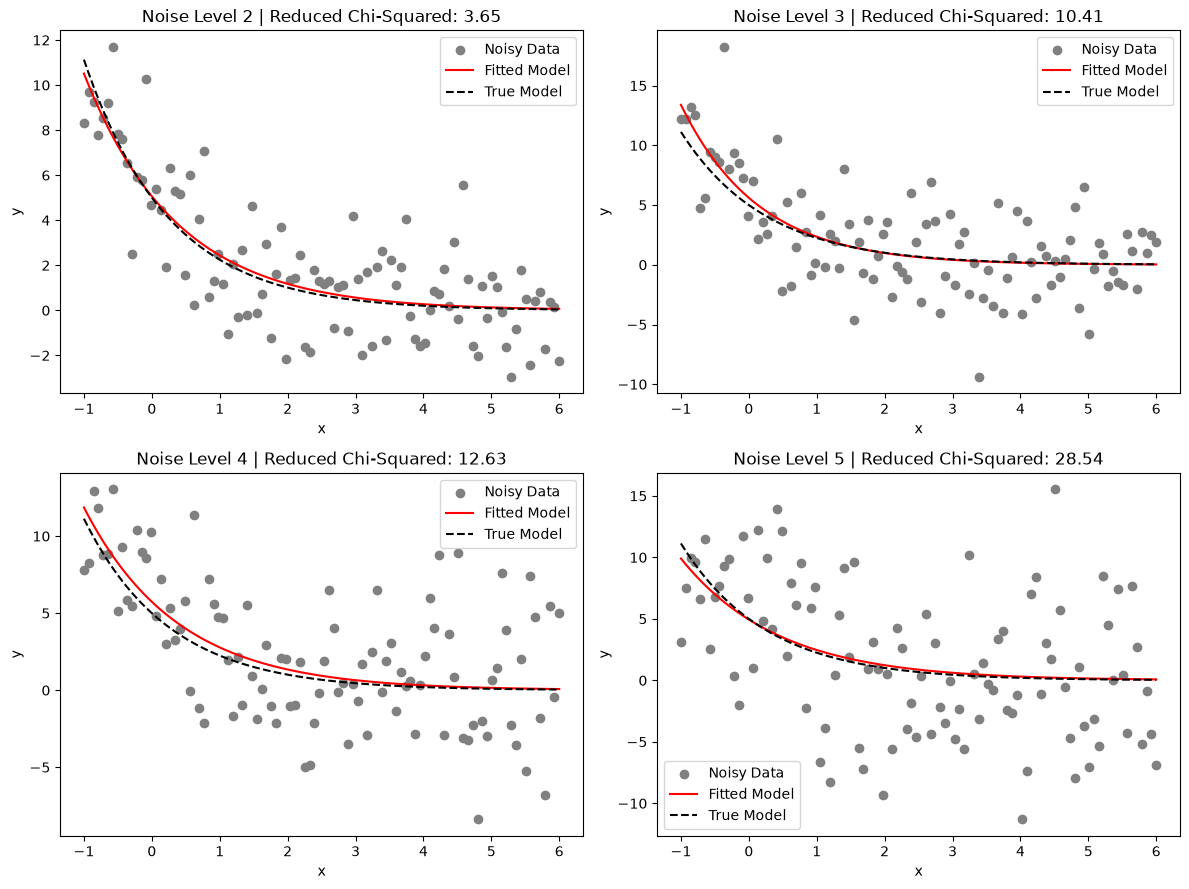

In [12]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y, p0=[1, 1])
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return A_fit, k_fit, chi2_reduced

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

noise_cols = ["y_noise_2", "y_noise_3", "y_noise_4", "y_noise_5"]

A1, k1, chi1 = fit_model(x, noisy_curvefit_data["y_noise_1"])
results = [[1, A1, k1, chi1]]

for i, col in enumerate(noise_cols):
    noise_level = i + 2
    y_data = noisy_curvefit_data[col]
    
    A_fit, k_fit, chi2_red = fit_model(x, y_data)
    results.append([noise_level, A_fit, k_fit, chi2_red])
    
    ax = axes[i]
    ax.scatter(x, y_data, color="gray", label="Noisy Data")
    ax.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted Model")
    ax.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True Model")
    
    ax.set_title(f"Noise Level {noise_level} | Reduced Chi-Squared: {chi2_red:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()

In [13]:
# 2.3.4

#As you increase noise level, red fitted curve diverges farther away from black dotted curve.
#Larger random scatter in data points pulls the least squares optimization away from the underlying true parameters.

#The reduced chi-squares increases significantly as noise increases.
#Because the numerator sums the sqaures residuals, larger vertical scatter directly increases the squared distances.

In [14]:
params_df = pd.DataFrame(
    results, 
    columns=["Noise level", "A_fit", "k_fit", "Reduced chi-squared"]
)

display(params_df)
params_df.to_csv("noisy_parameters.csv", index=False)

,Noise level,A_fit,k_fit,Reduced chi-squared
0,1,4.714814,0.918308,0.790673
1,2,5.063889,0.730396,3.649382
2,3,5.609396,0.870372,10.410207
3,4,5.738727,0.725965,12.626832
4,5,4.943458,0.695012,28.538124
